# Title: Homework 4: Fire scars with false color imagery 
- Author: Aaron Wang
- Github: https://github.com/AaronWanh/eds220-hwk4.git 

## About:
### Purpose: 
The goal of this notebook is use the satellite imagery to visualize the regions that were affected by the Palisades and Eaton fire using both true color and false color imagery. Using the perimeter geospatial datasets we can use create a boundary around the perimeter of the affected regionst to confirm. 

### Highlights:
1. Restoring Geospatial Information
2. True Color Image Map
3. False Color Image Map
4. Final Map (adding fire perimeter to false color map)

### Data:
* Landsat: This dataset contains Landsat 8 Collection 2 Level 2 surface reflectance data that is composed of a collection of spectral bands including red, blue, green bands and various infrared wavelengths to map out the surface of the Earth specifically in the LA region. Using these bands, allows us to create true and false color images. 
* Eaton Perimeter: This dataset provides geospatial data of the fires of Eaton Canyon. It shows the region of California that was affected by the fire.
* Palisades Perimeter: This dataset provides geospatial data of the fires of the Palisades area. It shows the region of California that was affected by the fire.

### References: 

* Microsoft planetary computer. (2024). Microsoft.Com. https://planetarycomputer.microsoft.com/dataset/landsat-c2-l2
* Palisades and Eaton dissolved fire perimeters (2025). (2025). Arcgis.Com. https://egis-lacounty.hub.arcgis.com/maps/ad51845ea5fb4eb483bc2a7c38b2370c/about


In [1]:
import os 

import pandas as pd 
import geopandas as gpd
import xarray as xr
import numpy as np

eaton = gpd.read_file("data/Eaton_Perimeter_20250121.geojson")
palisades = gpd.read_file("data/Palisades_Perimieter_20250121.geojson")

landsat8 = xr.open_dataset("data/landsat8-2025-02-23-palisades-eaton.nc",  engine="h5netcdf")

ERROR 1: PROJ: proj_create_from_database: Open of /opt/miniforge3/envs/eds220-v2/share/proj failed


In [ ]:
%pip install --user h5netcdf

In [ ]:
%pip install --user h5py

## Fire Perimeter Data Exploration 

In [18]:
eaton.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NAME,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Area,Shape__Length,geometry
0,1,2025,CA,CDF,LAC,EATON,Heat Perimeter,00009087,{72660ADC-B5EF-4D96-A33F-B4EA3740A4E3},2025-01-08 00:00:00+00:00,...,14056.26,None,None,None,None,000a99c2-0fef-4960-a3c4-f2342a0cd291,2020-2025,0.005564,0.859026,"MULTIPOLYGON (((398527.261 3781198.912, 398530..."


In [19]:
palisades.head()

,OBJECTID,YEAR_,STATE,AGENCY,UNIT_ID,FIRE_NAME,type,INC_NUM,IRWINID,ALARM_DATE,...,GIS_ACRES,COMMENTS,COMPLEX_NAME,COMPLEX_ID,FIRE_NUM,GlobalID,DECADES,Shape__Area,Shape__Length,geometry
0,1,2025,CA,CDF,LDF,PALISADES,Heat Perimeter,00000738,{A7EA5D21-F882-44B8-BF64-44AB11059DC1},2025-01-07 00:00:00+00:00,...,23448.88,None,None,None,None,8aea8178-a9d8-4c10-a7fd-d1371091b114,2020-2025,0.009268,1.157614,"MULTIPOLYGON (((359697.447 3766520.045, 359684..."


In [20]:
print(eaton.shape)           # rows (features) and columns
print(eaton.columns)         # attribute names
print(eaton.dtypes)

(1, 24)
Index(['OBJECTID', 'YEAR_', 'STATE', 'AGENCY', 'UNIT_ID', 'FIRE_NAME', 'type',
       'INC_NUM', 'IRWINID', 'ALARM_DATE', 'CONT_DATE', 'CAUSE', 'C_METHOD',
       'OBJECTIVE', 'GIS_ACRES', 'COMMENTS', 'COMPLEX_NAME', 'COMPLEX_ID',
       'FIRE_NUM', 'GlobalID', 'DECADES', 'Shape__Area', 'Shape__Length',
       'geometry'],
      dtype='object')
OBJECTID                       int64
YEAR_                          int64
STATE                         object
AGENCY                        object
UNIT_ID                       object
FIRE_NAME                     object
type                          object
INC_NUM                       object
IRWINID                       object
ALARM_DATE       datetime64[ns, UTC]
CONT_DATE        datetime64[ns, UTC]
CAUSE                          int64
C_METHOD                       int64
OBJECTIVE                      int64
GIS_ACRES                    float64
COMMENTS                      object
COMPLEX_NAME                  object
COMPLEX_ID      

In [21]:
print(eaton.crs)                  
print(eaton.crs.is_projected)    
print(eaton.crs.is_geographic) 

EPSG:32611
True
False


In [22]:
print(palisades.crs)                  
print(palisades.crs.is_projected)    
print(palisades.crs.is_geographic) 

EPSG:32611
True
False


## NetCDF data import and exploration

In [9]:
landsat8

<xarray.Dataset> Size: 78MB
Dimensions:      (y: 1418, x: 2742)
Coordinates:
  * y            (y) float64 11kB 3.799e+06 3.799e+06 ... 3.757e+06 3.757e+06
  * x            (x) float64 22kB 3.344e+05 3.344e+05 ... 4.166e+05 4.166e+05
    time         datetime64[ns] 8B 2025-02-23T18:28:13.651369
    spatial_ref  int64 8B 0
Data variables:
    red          (y, x) float32 16MB 1.024e+04 9.886e+03 ... 1.019e+04 9.967e+03
    green        (y, x) float32 16MB 9.93e+03 9.687e+03 ... 9.984e+03 9.662e+03
    blue         (y, x) float32 16MB 9.29e+03 9.183e+03 ... 9.49e+03 9.187e+03
    nir08        (y, x) float32 16MB 1.331e+04 1.313e+04 ... 1.287e+04 1.306e+04
    swir22       (y, x) float32 16MB 1.43e+04 1.437e+04 ... 1.406e+04 1.329e+04

### Summary 

The variables consist of color bands and infrared wavelengths such as near-infrared and short wave infrared. Each variable has the same number of values and their data types are floats. THe dimensions are x = 2742 and y = 1418. The coordinates x and y are spaced 30 units apart with x representing east to west and y representing north to south. The datetime variable holds a single value or a single date. 

## Restoring Geospatial Information

In [2]:
print(landsat8.rio.crs) 

None


In [3]:
# check the coordinate system reference stored in landsat8
landsat8['spatial_ref'].crs_wkt

'PROJCS["WGS 84 / UTM zone 11N",GEOGCS["WGS 84",DATUM["WGS_1984",SPHEROID["WGS 84",6378137,298.257223563,AUTHORITY["EPSG","7030"]],AUTHORITY["EPSG","6326"]],PRIMEM["Greenwich",0,AUTHORITY["EPSG","8901"]],UNIT["degree",0.0174532925199433,AUTHORITY["EPSG","9122"]],AUTHORITY["EPSG","4326"]],PROJECTION["Transverse_Mercator"],PARAMETER["latitude_of_origin",0],PARAMETER["central_meridian",-117],PARAMETER["scale_factor",0.9996],PARAMETER["false_easting",500000],PARAMETER["false_northing",0],UNIT["metre",1,AUTHORITY["EPSG","9001"]],AXIS["Easting",EAST],AXIS["Northing",NORTH],AUTHORITY["EPSG","32611"]]'

In [4]:
# change the crs of landsat8 to the spatial reference 
landsat8 = landsat8.rio.write_crs(32611)

In [5]:
print(landsat8.rio.crs)

EPSG:32611


## True Color Image

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers).


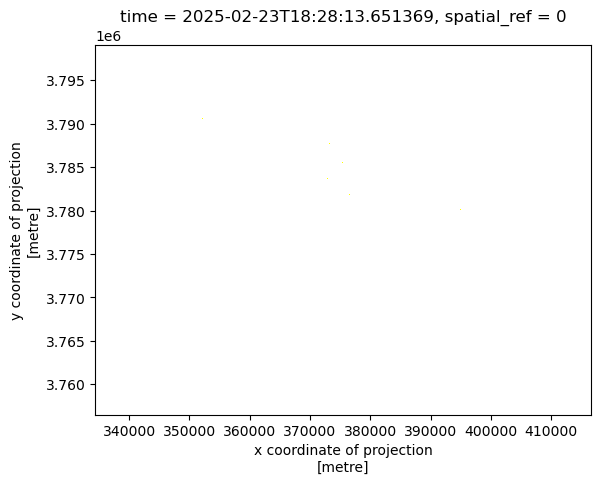

In [8]:
# map the true colors of the fires
landsat8[['red', 'green', 'blue']].to_dataarray().plot.imshow()


red False
green True
blue True
nir08 False
swir22 False


/opt/miniforge3/envs/eds220-v2/lib/python3.11/site-packages/matplotlib/cm.py:478: RuntimeWarning: invalid value encountered in cast
  xx = (xx * 255).astype(np.uint8)


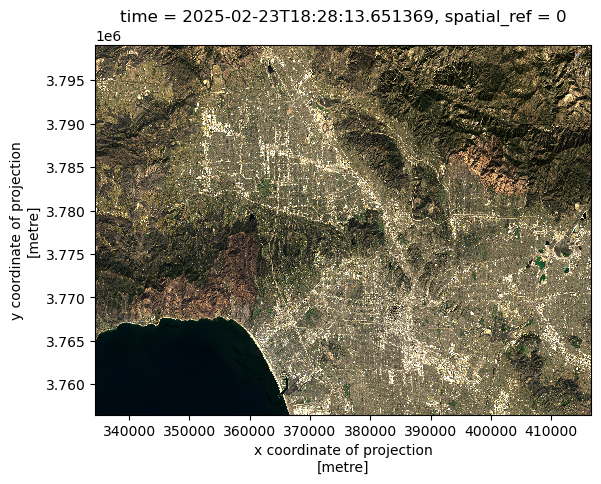

In [7]:
# check each band for NaN values
for bands in landsat8.data_vars:
    print(bands, np.isnan(landsat8[bands]).any().item())
    
# replace all NaN values with 0
landsat8 = landsat8.fillna(0)

# plot true colors 
landsat8[['red', 'green', 'blue']].to_dataarray().plot.imshow(robust = True)

The map from part A does not output anything because imshow() expects the floats value to be in between 0 and 1 but the band values are much larger. The map from part E visualizes the aftermath of the Palisades and Easton fires indicated from the brown hue on the map. 

## False Color Image

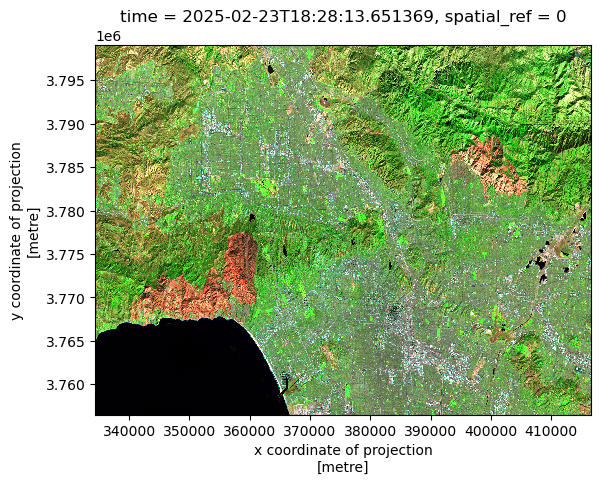

In [12]:
# plot false colors 
landsat8[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(robust = True)

## Map

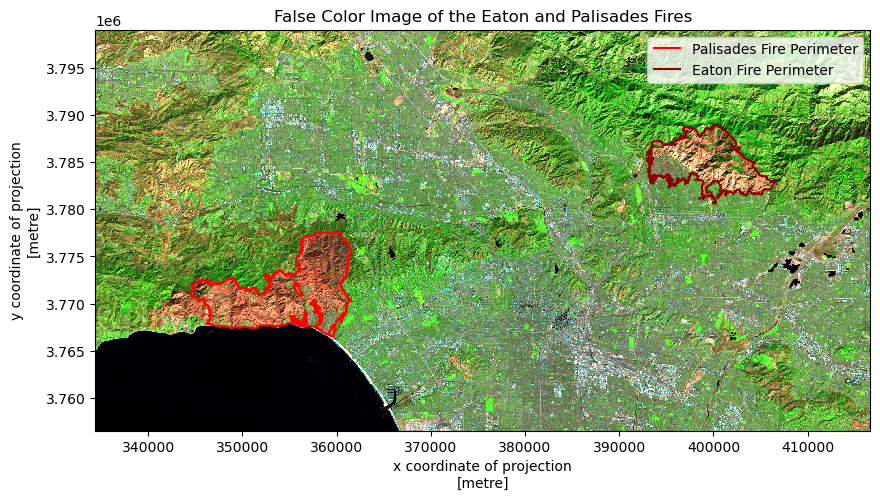

In [17]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(1, 1, figsize = (10,6))

# change crs of fire perimeters to match satellite data
palisades = palisades.to_crs("EPSG:32611")
eaton = eaton.to_crs("EPSG:32611")

landsat8[['swir22', 'nir08', 'red']].to_dataarray().plot.imshow(robust = True)

# add fire perimeter boundaries to the fire areas
palisades.boundary.plot(ax = ax, color = 'red', linewidth = 1.5, label = 'Palisades Fire Perimeter')
eaton.boundary.plot(ax = ax, color = 'darkred', linewidth = 1.5, label = 'Eaton Fire Perimeter')

ax.legend()
ax.set_title('False Color Image of the Eaton and Palisades Fires')
plt.show()

The map demonstrates where the fire were located in Los Angeles. The fire next to the coast is the Palisades fire and the fire closer to the mountains is the Eaton fire. The false color imagery allows us to visualizes the areas that were affected by creating constrasting colors with a red, brown hue. 